# Evolução do capital das carteiras

Este relatório lê uma execução concluída do comando `portfolio`. As operações foram calculadas previamente com os sinais do SVM ajustado e os sorteios compartilhados. Cada trajetória começa com 10.000 USDT e acumula o saldo ao longo de todo o período.

Execute antes, no terminal: `python -m tcc_crypto.experiment portfolio --run-id portfolio_01`.

In [1]:
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
from tcc_crypto import experiment

run_id = "portfolio_01"
report = experiment.load_portfolio_report(run_id)


Matplotlib is building the font cache; this may take a moment.


## Identificação e resumo

A origem identifica o treinamento reutilizado. As datas dos gráficos correspondem aos dias de operação em UTC. Dias em caixa mantêm o saldo. Previsões repetidas e candles preenchidos permanecem identificados para avaliar essas hipóteses da simulação.

In [2]:
tables = report["tables"]
capital = tables["capital"].copy()
signals = tables["signals"]
operations = tables["operations"]
strategy_labels = {
    "svm_min_variance": "SVM + mínima variância",
    "random_min_variance": "Aleatório + mínima variância",
    "svm_equal_weight": "SVM + pesos iguais",
    "random_equal_weight": "Aleatório + pesos iguais",
}
colors = dict(zip(strategy_labels, ["#1768AC", "#E67E22", "#238B45", "#8E44AD"]))
display(pd.DataFrame([{
    "Execução da carteira": report["run_id"],
    "Execução do treinamento": report["source"]["run_id"],
    "Modelo": report["configuration"]["source"]["model"],
    "Primeiro dia (UTC)": capital.operation_date.min(),
    "Último dia (UTC)": capital.operation_date.max(),
}]))
summary = capital.sort_values("operation_date").groupby(["target", "strategy"]).agg(
    final_capital=("closing_capital", "last"),
    cash_days=("cash_reason", lambda values: values.ne("").sum()),
)
summary = summary.reset_index()
summary["strategy"] = summary.strategy.map(strategy_labels)
display(summary.rename(columns={"target": "Target", "strategy": "Estratégia", "final_capital": "Capital final (USDT)", "cash_days": "Dias em caixa"}))
display(signals.groupby("target").signal_reused.sum().rename("Previsões repetidas").to_frame())
display(operations.loc[operations.weight.gt(0)].groupby(["target", "strategy"]).operation_is_imputed.sum().rename("Operações com candle preenchido").to_frame())


,Execução da carteira,Execução do treinamento,Modelo,Primeiro dia (UTC),Último dia (UTC)
0,portfolio_01,full_01,tuned_svc,2019-08-31 00:00:00+00:00,2026-09-01 00:00:00+00:00


,Target,Estratégia,Capital final (USDT),Dias em caixa
0,target_1pct,Aleatório + pesos iguais,7188.128545,0
1,target_1pct,Aleatório + mínima variância,7491.595335,0
2,target_1pct,SVM + pesos iguais,8744.074768,0
3,target_1pct,SVM + mínima variância,45010.932846,0
4,target_2pct,Aleatório + pesos iguais,7962.427760,0
5,target_2pct,Aleatório + mínima variância,13192.891993,0
6,target_2pct,SVM + pesos iguais,8398.970134,0
7,target_2pct,SVM + mínima variância,13430.912332,0
8,target_3pct,Aleatório + pesos iguais,12839.610628,0
9,target_3pct,Aleatório + mínima variância,15711.772787,0


,Previsões repetidas
target,
target_1pct,9694
target_2pct,2255
target_3pct,3914


Operações com candle preenchido
target      strategy                                            
target_1pct random_equal_weight                                0
            random_min_variance                                0
            svm_equal_weight                                   0
            svm_min_variance                                   0
target_2pct random_equal_weight                                0
            random_min_variance                                0
            svm_equal_weight                                   0
            svm_min_variance                                   0
target_3pct random_equal_weight                                0
            random_min_variance                                0
            svm_equal_weight                                   0
            svm_min_variance                                   0

## Target de 1%

Cada curva acompanha uma carteira independente. O primeiro ponto representa o capital disponível antes da primeira operação. Os demais mostram o saldo ao final de cada dia. A regra realiza 1% quando o alvo é atingido e usa o retorno entre abertura e fechamento nos demais casos.

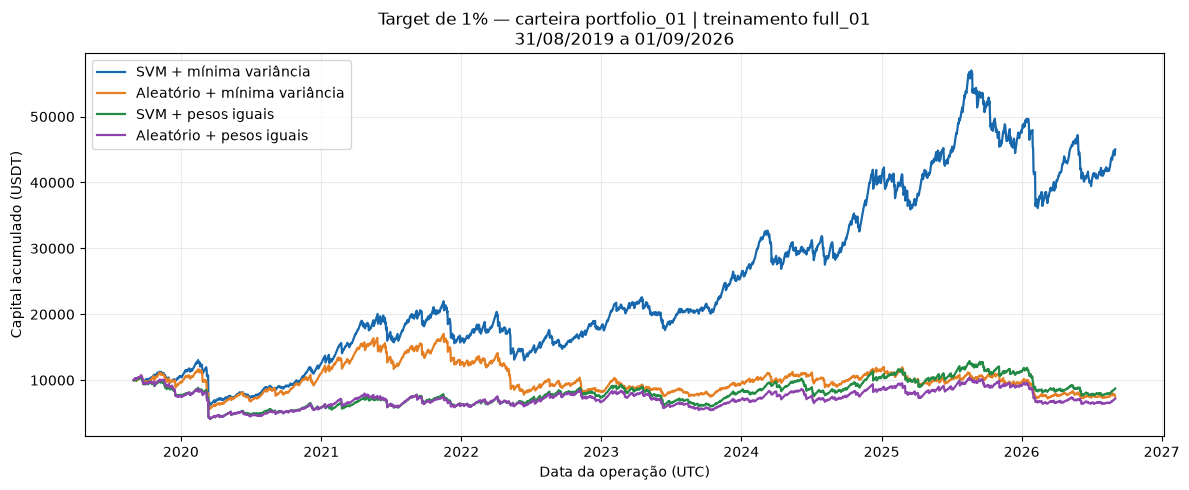

In [3]:
target = "target_1pct"
selected = capital.loc[capital.target.eq(target)].sort_values("operation_date")
fig, ax = plt.subplots(figsize=(12, 5))
for strategy, label in strategy_labels.items():
    curve = selected.loc[selected.strategy.eq(strategy)]
    times = [curve.operation_date.iloc[0], *(curve.operation_date + pd.Timedelta(days=1) - pd.Timedelta(milliseconds=1))]
    balances = [curve.opening_capital.iloc[0], *curve.closing_capital]
    ax.plot(times, balances, label=label, color=colors[strategy], linewidth=1.6)
ax.set_title(f"Target de 1% — carteira {report['run_id']} | treinamento {report['source']['run_id']}\n{selected.operation_date.min():%d/%m/%Y} a {selected.operation_date.max():%d/%m/%Y}")
ax.set_xlabel("Data da operação (UTC)")
ax.set_ylabel("Capital acumulado (USDT)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


## Target de 2%

Cada curva acompanha uma carteira independente. O primeiro ponto representa o capital disponível antes da primeira operação. Os demais mostram o saldo ao final de cada dia. A regra realiza 2% quando o alvo é atingido e usa o retorno entre abertura e fechamento nos demais casos.

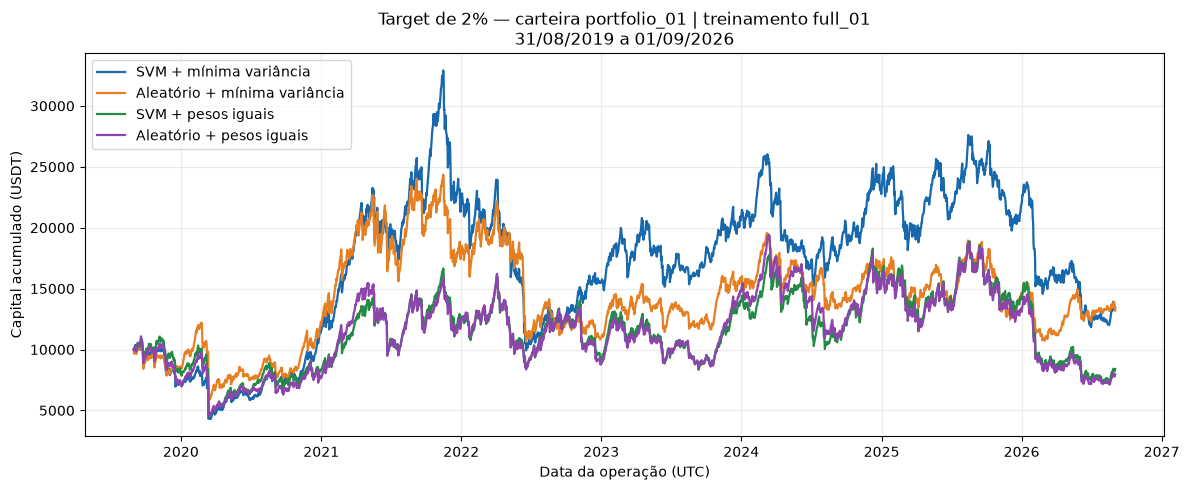

In [4]:
target = "target_2pct"
selected = capital.loc[capital.target.eq(target)].sort_values("operation_date")
fig, ax = plt.subplots(figsize=(12, 5))
for strategy, label in strategy_labels.items():
    curve = selected.loc[selected.strategy.eq(strategy)]
    times = [curve.operation_date.iloc[0], *(curve.operation_date + pd.Timedelta(days=1) - pd.Timedelta(milliseconds=1))]
    balances = [curve.opening_capital.iloc[0], *curve.closing_capital]
    ax.plot(times, balances, label=label, color=colors[strategy], linewidth=1.6)
ax.set_title(f"Target de 2% — carteira {report['run_id']} | treinamento {report['source']['run_id']}\n{selected.operation_date.min():%d/%m/%Y} a {selected.operation_date.max():%d/%m/%Y}")
ax.set_xlabel("Data da operação (UTC)")
ax.set_ylabel("Capital acumulado (USDT)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


## Target de 3%

Cada curva acompanha uma carteira independente. O primeiro ponto representa o capital disponível antes da primeira operação. Os demais mostram o saldo ao final de cada dia. A regra realiza 3% quando o alvo é atingido e usa o retorno entre abertura e fechamento nos demais casos.

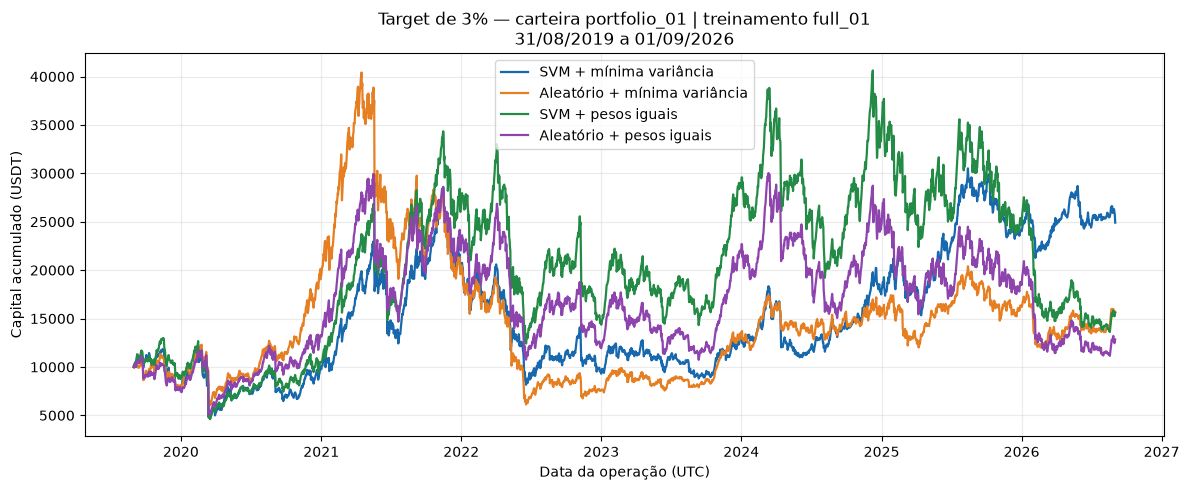

In [5]:
target = "target_3pct"
selected = capital.loc[capital.target.eq(target)].sort_values("operation_date")
fig, ax = plt.subplots(figsize=(12, 5))
for strategy, label in strategy_labels.items():
    curve = selected.loc[selected.strategy.eq(strategy)]
    times = [curve.operation_date.iloc[0], *(curve.operation_date + pd.Timedelta(days=1) - pd.Timedelta(milliseconds=1))]
    balances = [curve.opening_capital.iloc[0], *curve.closing_capital]
    ax.plot(times, balances, label=label, color=colors[strategy], linewidth=1.6)
ax.set_title(f"Target de 3% — carteira {report['run_id']} | treinamento {report['source']['run_id']}\n{selected.operation_date.min():%d/%m/%Y} a {selected.operation_date.max():%d/%m/%Y}")
ax.set_xlabel("Data da operação (UTC)")
ax.set_ylabel("Capital acumulado (USDT)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()
